In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sid321axn/malicious-urls-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'malicious-urls-dataset' dataset.
Path to dataset files: /kaggle/input/malicious-urls-dataset


In [2]:
!pip install tldextract

In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import re
import tldextract
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [2]:
df = pd.read_csv('/kaggle/input/malicious-urls-dataset/malicious_phish.csv')
df.head()

,url,type
0,br-icloud.com.br,phishing
1,mp3raid.com/music/krizz_kaliko.html,benign
2,bopsecrets.org/rexroth/cr/1.htm,benign
3,http://www.garage-pirenne.be/index.php?option=...,defacement
4,http://adventure-nicaragua.net/index.php?optio...,defacement


In [5]:
df.type.value_counts()

,count
type,
benign,428103
defacement,96457
phishing,94111
malware,32520


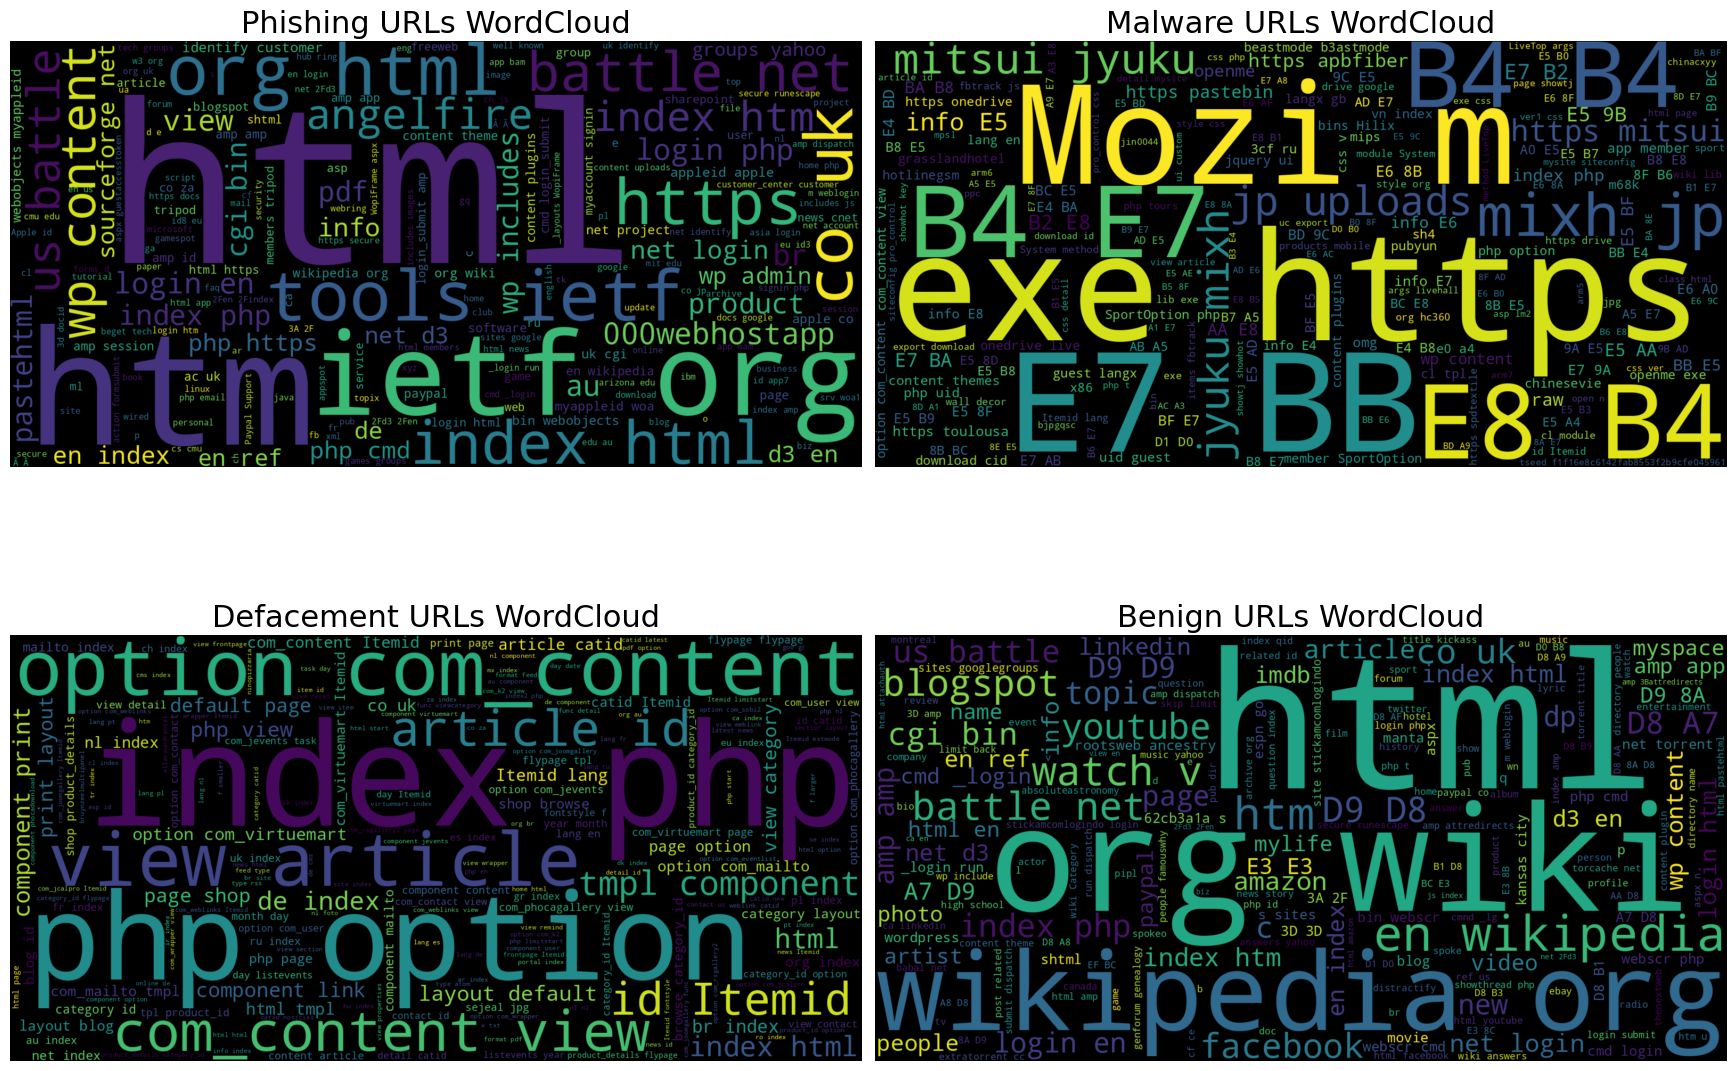

In [86]:
# Separate data by class
categories = {
    "Phishing": df[df.type == "phishing"],
    "Malware": df[df.type == "malware"],
    "Defacement": df[df.type == "defacement"],
    "Benign": df[df.type == "benign"]
}

# Create 2x2 figure
fig, axes = plt.subplots(2, 2, figsize=(18, 14), facecolor="white")
axes = axes.ravel()

for i, (label, subset) in enumerate(categories.items()):
    urls = " ".join(subset["url"].astype(str))

    wc = WordCloud(
        width=1600,
        height=800,
        colormap="viridis",
        background_color="black"
    ).generate(urls)

    axes[i].imshow(wc, interpolation="bilinear")
    axes[i].set_title(f"{label} URLs WordCloud", fontsize=22, color="black")
    axes[i].axis("off")

plt.tight_layout(pad=3, h_pad=1, w_pad=1)
plt.show()


In [84]:
def clean_url(url):
    url = url.replace("https://", "")
    url = url.replace("http://", "")
    url = url.replace("www.", "")
    return url.lower()

df["clean"] = df.url.apply(clean_url)


In [100]:
# Encode labels
label_encoder = LabelEncoder()
df['label_encoded'] = label_encoder.fit_transform(df['type'])

# TF-IDF Vectorizer for URLs
vectorizer = TfidfVectorizer(
    analyzer='char',
    ngram_range=(3, 5),   # character-level n-grams (best for URL detection)
    max_features=5000
)

X = vectorizer.fit_transform(df['url'])
y = df['label_encoded']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train.shape, X_test.shape


((520952, 5000), (130239, 5000))

In [87]:
# Random Forest
rf = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42)

# Logistic Regression
lr = LogisticRegression(max_iter=1000)

# XGBoost (smaller)
xgb = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    use_label_encoder=False,
    tree_method='hist',
    random_state=42
)


In [11]:
rf.fit(X_train, y_train)    # Train RF
lr.fit(X_train, y_train)    # Then LR
xgb.fit(X_train, y_train)   # Then XGB

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [15:23:48] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)


========== Random Forest Evaluation ==========
Accuracy : 0.8501
Precision: 0.8638
Recall   : 0.8501
F1-Score : 0.8093

Classification Report:
              precision    recall  f1-score   support

           0       0.83      1.00      0.91     85621
           1       0.91      0.92      0.92     19292
           2       0.91      0.74      0.82      6504
           3       0.94      0.14      0.25     18822

    accuracy                           0.85    130239
   macro avg       0.90      0.70      0.72    130239
weighted avg       0.86      0.85      0.81    130239



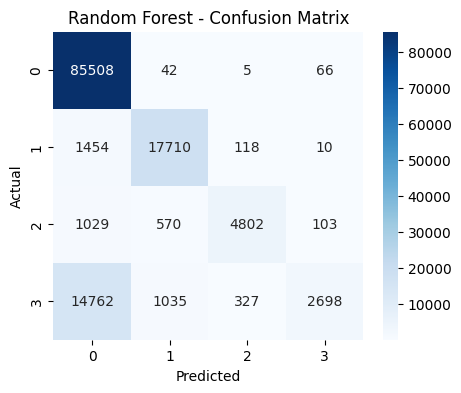


========== Logistic Regression Evaluation ==========
Accuracy : 0.9543
Precision: 0.9534
Recall   : 0.9543
F1-Score : 0.9535

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.98      0.97     85621
           1       0.97      0.98      0.98     19292
           2       0.97      0.92      0.94      6504
           3       0.88      0.81      0.85     18822

    accuracy                           0.95    130239
   macro avg       0.95      0.93      0.94    130239
weighted avg       0.95      0.95      0.95    130239



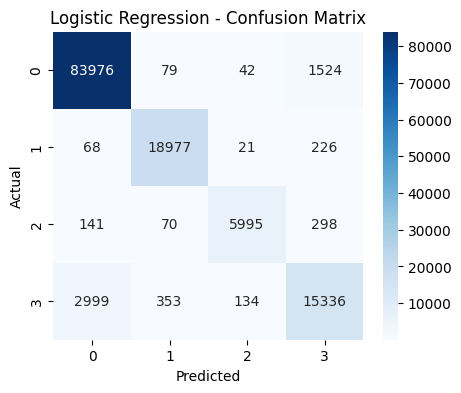


========== XGBoost Evaluation ==========
Accuracy : 0.9274
Precision: 0.9255
Recall   : 0.9274
F1-Score : 0.9242

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.98      0.96     85621
           1       0.93      0.95      0.94     19292
           2       0.96      0.84      0.90      6504
           3       0.87      0.68      0.76     18822

    accuracy                           0.93    130239
   macro avg       0.92      0.86      0.89    130239
weighted avg       0.93      0.93      0.92    130239



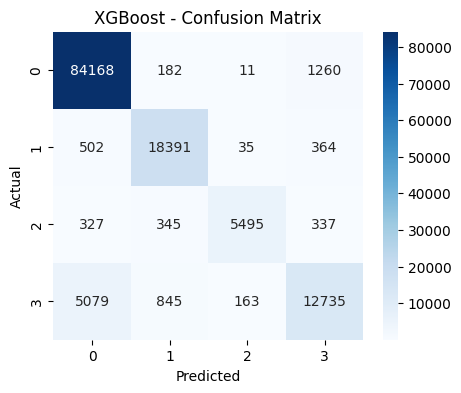

In [15]:
# Make predictions
rf_pred = rf.predict(X_test)
lr_pred = lr.predict(X_test)
xgb_pred = xgb.predict(X_test)

# Store predictions
predictions = {
    "Random Forest": rf_pred,
    "Logistic Regression": lr_pred,
    "XGBoost": xgb_pred
}

# Evaluate each model
for name, y_pred in predictions.items():
    print(f"\n========== {name} Evaluation ==========")

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted')
    rec  = recall_score(y_test, y_pred, average='weighted')
    f1   = f1_score(y_test, y_pred, average='weighted')

    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-Score : {f1:.4f}")

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


In [52]:
import random

# Take 5 random samples from the dataset
sample_df = df.sample(5)

print("Testing random samples from dataset...\n")

for idx, row in sample_df.iterrows():
    url_clean = clean_url(row['url'])
    vect = vectorizer.transform([url_clean])

    # Predictions
    rf_pred = rf.predict(vect)[0]
    lr_pred = lr.predict(vect)[0]
    xgb_pred = xgb.predict(vect)[0]

    # Decode labels
    rf_label = label_encoder.inverse_transform([rf_pred])[0]
    lr_label = label_encoder.inverse_transform([lr_pred])[0]
    xgb_label = label_encoder.inverse_transform([xgb_pred])[0]

    true_label = row['type']

    # Print results
    print(f"URL: {row['url']}")
    print(f"True Label: {true_label}")
    print(f"Random Forest: {rf_label} {'✅' if rf_label==true_label else '❌'}")
    print(f"Logistic Regression: {lr_label} {'✅' if lr_label==true_label else '❌'}")
    print(f"XGBoost: {xgb_label} {'✅' if xgb_label==true_label else '❌'}")
    print("-"*60)


Testing random samples from dataset...

URL: en.wikipedia.org/wiki/Tom_Sawyer_Software
True Label: benign
Random Forest: benign ✅
Logistic Regression: benign ✅
XGBoost: benign ✅
------------------------------------------------------------
URL: people.famouswhy.com/raquel_houghton/
True Label: benign
Random Forest: benign ✅
Logistic Regression: benign ✅
XGBoost: benign ✅
------------------------------------------------------------
URL: http://9779.info/%E8%A1%8D%E7%BA%B8%E8%B4%B4%E7%94%BB%E5%9B%BE%E7%89%87%E6%AC%A3%E8%B5%8F/
True Label: malware
Random Forest: benign ❌
Logistic Regression: malware ✅
XGBoost: benign ❌
------------------------------------------------------------
URL: player.streamtheworld.com/_players/maverick/index.php?callsign=WDOHFM
True Label: benign
Random Forest: benign ✅
Logistic Regression: benign ✅
XGBoost: benign ✅
------------------------------------------------------------
URL: ebay.com/itm/1985-86-Concordia-Stingers-Hockey-Schedule-/130254841702
True Label: be

In [16]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.0/9.0 MB 44.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 81.3 MB/s eta 0:00:00


In [104]:
import pickle
import streamlit as st

# Load TF-IDF vectorizer
with open("vectorizer.pkl", "wb") as f:
    pickle.dump(vectorizer, f)

# Load trained models
with open("rf_model.pkl", "rb") as f:
    rf = pickle.load(f)

with open("lr_model.pkl", "rb") as f:
    lr = pickle.load(f)

with open("xgb_model.pkl", "wb") as f:
    pickle.dump(xgb, f)

print("Models and vectorizer loaded successfully!")


Models and vectorizer loaded successfully!


In [27]:
!pip install streamlit pyngrok

In [101]:
%%writefile app.py
import streamlit as st
import pickle
import pandas as pd

# --- Load vectorizer and models ---
with open("vectorizer.pkl", "rb") as f:
    vectorizer = pickle.load(f)
with open("rf_model.pkl", "rb") as f:
    rf = pickle.load(f)
with open("lr_model.pkl", "rb") as f:
    lr = pickle.load(f)
with open("xgb_model.pkl", "rb") as f:
    xgb = pickle.load(f)

# Labels mapping
labels = {0: "Benign", 1: "Defacement", 2: "Phishing", 3: "Malware"}

#  Helper function
def clean_url(url):
    url = url.replace("https://", "").replace("http://", "").replace("www.", "")
    return url.lower()

# Initialize session state for history
if 'history' not in st.session_state:
    st.session_state['history'] = []

# Streamlit UI
st.title("Malicious URL Detection")
st.write("Enter a URL to classify it as Benign, Phishing, Malware, or Defacement.")
st.info("Example URLs: https://www.google.com, http://malicious-site.com/login")

url_input = st.text_input("Enter URL here:")

if st.button("Predict"):
    if not url_input.strip():
        st.warning("Please enter a URL to classify!")
    else:
        clean = clean_url(url_input)
        vect = vectorizer.transform([clean])
        models = {"Random Forest": rf, "Logistic Regression": lr, "XGBoost": xgb}

        prediction_results = []

        for name, model in models.items():
            pred = model.predict(vect)[0]
            probs = model.predict_proba(vect)[0]
            result = labels[pred]

            prediction_results.append({
                "Model": name,
                "Prediction": result,
                "Confidence": f"{max(probs)*100:.2f}%",
                "Probabilities": {labels[i]: f"{probs[i]*100:.2f}%" for i in range(len(probs))}
            })

        # Store in session history
        st.session_state.history.append({
            "URL": url_input,
            "Results": prediction_results
        })

# Display history
if st.session_state.history:
    st.subheader("Prediction History")
    for entry in reversed(st.session_state.history):
        st.write(f"**URL:** {entry['URL']}")
        for res in entry["Results"]:
            if res['Prediction'] == "Benign":
                st.success(f"{res['Model']}: {res['Prediction']} ({res['Confidence']})")
            else:
                st.error(f"{res['Model']}: {res['Prediction']} ({res['Confidence']})")
            st.write("Probabilities:", res["Probabilities"])
        st.write("---")


Overwriting app.py


In [92]:
!ls


app.py		   lr_model.pkl  sample_data  vectorizer.pkl
label_encoder.pkl  rf_model.pkl  scaler.pkl   xgb_model.pkl


In [102]:
!streamlit run app.py &>/dev/null &


In [103]:
from pyngrok import ngrok

public_url = ngrok.connect(8501)
print("🚀 Your Streamlit app is live at:", public_url)


🚀 Your Streamlit app is live at: NgrokTunnel: "https://avertable-nonoxidizing-avery.ngrok-free.dev" -> "http://localhost:8501"
